# Single neuron dynamics

# note: run this example with Python3 kernel

## libs and path

In [1]:
fileName = 'eg_single-cell' 

In [2]:
try:
    import pyNN.spiNNaker as sim
except ModuleNotFoundError:
    import pyNN.brian2 as sim
    
from pyNN import space 
import numpy as np
np.in1d = np.isin
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import scipy
import pickle
import pandas as pd
import seaborn as sns
import time
import datetime
import json
import warnings
warnings.filterwarnings('ignore')
import python_utils as pu

savePath = f'../outputs/' # remember to create the folder if not already present (mkdir ./notebooks/outputs)
dt_string = datetime.datetime.today().isoformat() # ISO8601 ! :-)
tag = dt_string 
saveName = f'{savePath}{fileName}-{tag}'
print(saveName)
PARS={}

import re
def sanitize_filename(s):
    return re.sub(r'[<>:"/\\|?*]', '-', s)  # set di caratteri vietati su Windows
saveName = sanitize_filename(saveName)
print(saveName)

WARNING    /home/jovyan/work/CNT/notebooks/intro/python_utils.py:25: DeprecationWarning: 
The `fooof` package is being deprecated and replaced by the `specparam` (spectral parameterization) package.
This version of `fooof` (1.1) is fully functional, but will not be further updated.
New projects are recommended to update to using `specparam` (see Changelog for details).
  from fooof import FOOOF
 [py.warnings]


../outputs/eg_single-cell-2026-05-26T09:48:08.356798
..-outputs-eg_single-cell-2026-05-26T09-48-08.356798


## sim setup

In [3]:
PARS['dt']=1 #ms
PARS['min_delay']=1 #ms
PARS['max_delay']=100 #ms
PARS['simtime']=800 #ms

sim.setup(
        timestep=PARS['dt'],
        min_delay=PARS['min_delay'],
        max_delay=PARS['max_delay'])

simtime = PARS['simtime']

## network design

In [4]:
MODEL=sim.IF_cond_exp
N_CELLS = 1

netPars={'v_rest': -65.0, 
      'v_thresh': -37.0, 
      'v_reset': -80.0,
      'cm': 1.0, 
      'tau_m': 20.0, 
      'tau_refrac': 0.1, 
      'tau_syn_E': 50.0, 
      'tau_syn_I': 5.0, 
      'e_rev_E': 0.0, 
      'e_rev_I': -70.0, 
      'i_offset': 0.0}

cell0 = sim.Population(N_CELLS, 
                      MODEL, 
                      cellparams=netPars,
                      label='cell0')

cell0.record(['v', 'gsyn_exc', 'gsyn_inh', 'spikes'])


WARNING    /opt/conda/lib/python3.13/site-packages/pyNN/common/populations.py:680: DeprecationWarning: Passing celltype class and parameters separately is deprecated. Please instantiate the celltype with the parameters before passing to the Population
  warnings.warn(
 [py.warnings]


## input design

In [5]:
# not implemented in sPyNNaker
PARS['AC-start']=100 # ms
PARS['AC-stop']=400 # ms
PARS['AC-amplitude']=10 # nA
PARS['AC-frequency']=10 # Hz


pulse = sim.ACSource(start=PARS['AC-start'],
                     stop=PARS['AC-stop'],
                     amplitude=PARS['AC-amplitude'],
                     frequency=PARS['AC-frequency']
                     )

pulse.inject_into(cell0)
pulse.record()

###################
pulse2 = sim.StepCurrentSource(times=[600,610],
                              amplitudes=[10,0,])
pulse2.inject_into(cell0)
pulse2.record()


# simulation run

In [6]:
tic = time.time()
sim.run(PARS['simtime'])
toc = time.time() - tic
print(f'simulation time: {toc} [s]')


WARNING    /opt/conda/lib/python3.13/site-packages/brian2/parsing/statements.py:51: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  parsed = STATEMENT.parse_string(code, parseAll=True)
 [py.warnings]
INFO       No numerical integration method specified for group 'neurongroup', using method 'euler' (took 0.01s, trying other methods took 0.05s). [brian2.stateupdaters.base.method_choice]
WARNING    /opt/conda/lib/python3.13/site-packages/brian2/parsing/statements.py:51: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  parsed = STATEMENT.parse_string(code, parseAll=True)
 [py.warnings]
WARNING    /opt/conda/lib/python3.13/site-packages/brian2/parsing/statements.py:51: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  parsed = STATEMENT.parse_string(code, parseAll=True)
 [py.warnings]
WARNING    /opt/conda/lib/python3.13/site-packages/brian2/parsing/statements.py:51: PyparsingDeprecationWarnin

simulation time: 0.6901304721832275 [s]


# save results

In [7]:
for recording in ['v', 'gsyn_inh', 'gsyn_exc', 'spikes']:
    cell0.write_data(f'{saveName}-{recording}.pkl')

In [8]:
#cell0.get_data()

In [9]:
v0=cell0.get_data(variables=['v']).segments[0].analogsignals[0]
ge0=cell0.get_data(variables=['gsyn_exc']).segments[0].analogsignals[0]
gi0=cell0.get_data(variables=['gsyn_inh']).segments[0].analogsignals[0]
spikes0=cell0.get_data(variables=['spikes']).segments[0].spiketrains[0]
i=pulse.get_data()
stepPulse=pulse2.get_data()


In [10]:
PARS['v-mean']=v0.magnitude.mean()
PARS['gsyn_exc-mean']=ge0.magnitude.mean()
PARS['gsyn_inh-mean']=gi0.magnitude.mean()
PARS['fr-mean']=cell0.get_spike_counts()

In [11]:
JSON=dict(**PARS,**netPars)
with open(f'{saveName}.json', 'w') as json_file:
    json.dump(JSON, json_file)
JSON

{'dt': 1,
 'min_delay': 1,
 'max_delay': 100,
 'simtime': 800,
 'AC-start': 100,
 'AC-stop': 400,
 'AC-amplitude': 10,
 'AC-frequency': 10,
 'v-mean': np.float64(-83.21731985242472),
 'gsyn_exc-mean': np.float64(0.0),
 'gsyn_inh-mean': np.float64(0.0),
 'fr-mean': {0: 18},
 'v_rest': -65.0,
 'v_thresh': -37.0,
 'v_reset': -80.0,
 'cm': 1.0,
 'tau_m': 20.0,
 'tau_refrac': 0.1,
 'tau_syn_E': 50.0,
 'tau_syn_I': 5.0,
 'e_rev_E': 0.0,
 'e_rev_I': -70.0,
 'i_offset': 0.0}

cell0 spikes: {0: 18}


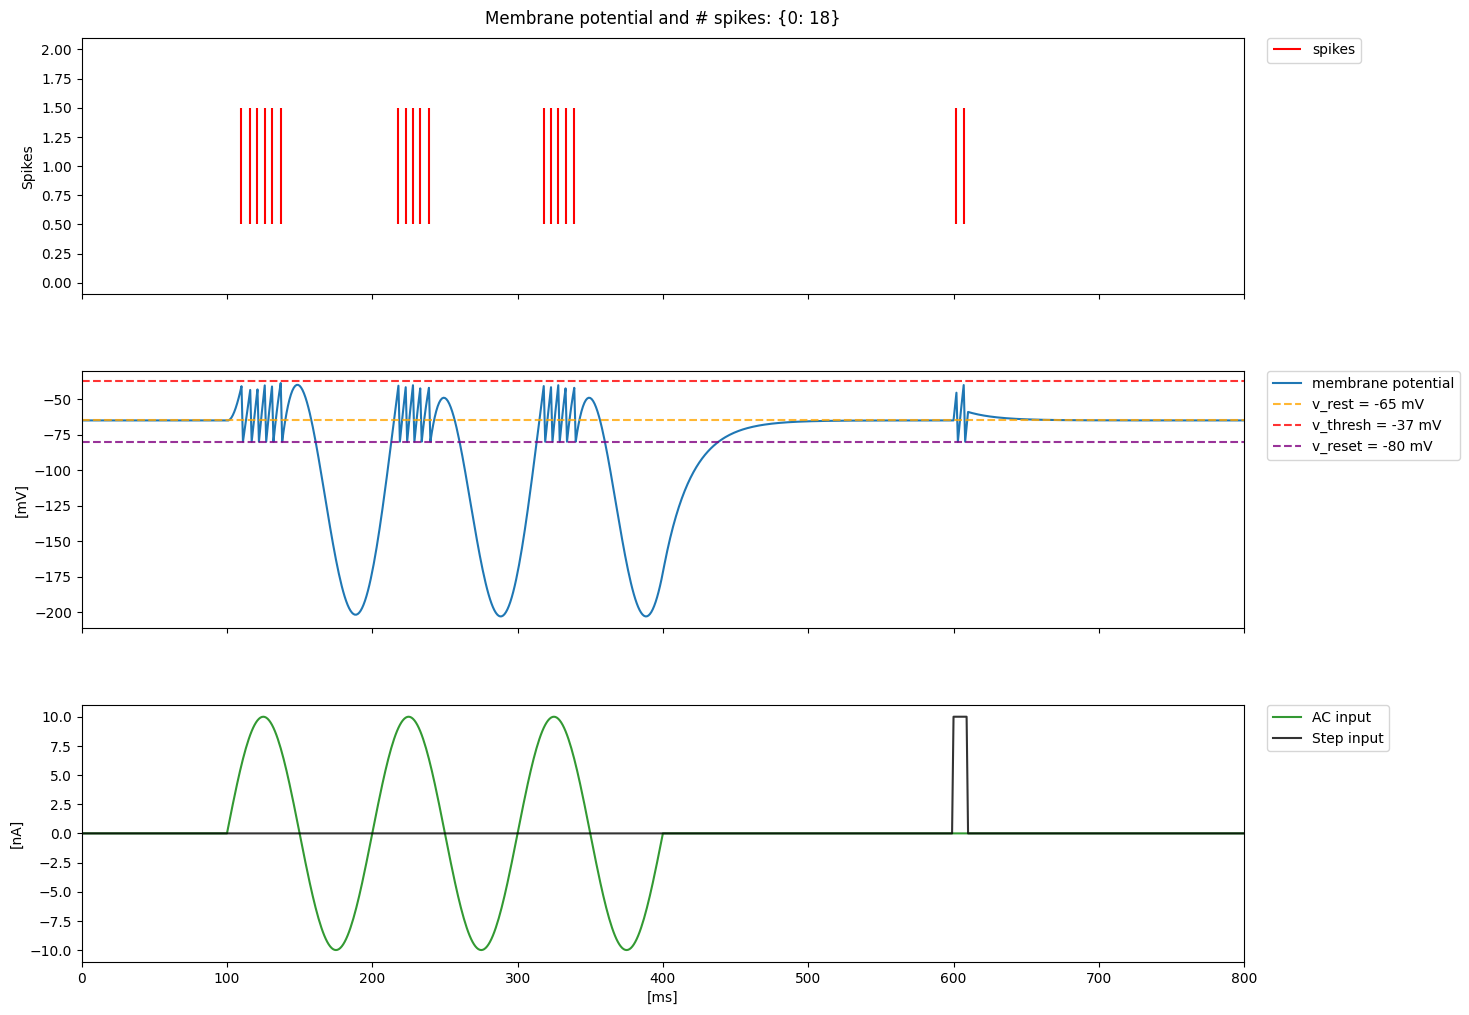

In [16]:
import matplotlib.pyplot as plt
import numpy as np

print(f"cell0 spikes: {cell0.get_spike_counts()}")

# Creiamo 3 pannelli verticali condividendo l'asse X per un perfetto allineamento temporale
# sharex=True fa in modo che lo zoom o i limiti su un asse si applichino a tutti
fig, axs = plt.subplots(3, 1, figsize=(10*1.5, 8*1.5), sharex=True)
fig.subplots_adjust(hspace=0.3)  # Spazio verticale tra i pannelli

# Assegniamo nomi comodi ai singoli pannelli
ax_spikes = axs[0]
ax_v = axs[1]
ax_curr = axs[2]

# ==========================================
# 1. PANNELLO ALTO: Spikes (Raster Plot)
# ==========================================
line_spk = ax_spikes.eventplot(
    np.array(list(spikes0)).T, color="r", alpha=1, label="spikes"
)
ax_spikes.set_ylabel("Spikes")
ax_spikes.set_title(
    f"Membrane potential and # spikes: {cell0.get_spike_counts()}", pad=10
)
# Legenda a lato
ax_spikes.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)

# ==========================================
# 2. PANNELLO CENTRALE: Potenziale di Membrana
# ==========================================
line_v = ax_v.plot(v0, label="membrane potential", color="tab:blue")
h1 = ax_v.axhline(
    -65, label="v_rest = -65 mV", c="orange", alpha=0.8, linestyle="--"
)
h2 = ax_v.axhline(
    -37, label="v_thresh = -37 mV", c="red", alpha=0.8, linestyle="--"
)
h3 = ax_v.axhline(
    -80, label="v_reset = -80 mV", c="purple", alpha=0.8, linestyle="--"
)
ax_v.set_ylabel("[mV]")

# Raccogliamo tutte le linee di questo pannello per la legenda unica
lines_v = line_v + [h1, h2, h3]
labels_v = [l.get_label() for l in lines_v]
ax_v.legend(
    lines_v, labels_v, loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0
)

# ==========================================
# 3. PANNELLO BASSO: Input di Corrente
# ==========================================
line_ac = ax_curr.plot(i, "green", alpha=0.8, label="AC input")
line_step = ax_curr.plot(stepPulse, "k", alpha=0.8, label="Step input")
ax_curr.set_ylabel("[nA]")
ax_curr.set_xlabel("[ms]")
ax_curr.set_xlim(0, simtime)

# Raccogliamo le linee della corrente per la legenda
lines_curr = line_ac + line_step
labels_curr = [l.get_label() for l in lines_curr]
ax_curr.legend(
    lines_curr,
    labels_curr,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0,
)

# Salva l'immagine includendo le legende esterne
fig.savefig(
    f"{saveName}.jpeg", dpi=100, bbox_inches="tight", facecolor="white"
)
plt.show()